# Лабораторная работа №1
## Низкоуровневый анализ, предобработка текста и статистическое языковое моделирование

**Датасет:** Phishing Email Dataset (`datasets/phishing_email/`).

* **Основной корпус** — `phishing_email.csv`: 82 486 писем, колонки `text_combined` (текст) и `label` (1 — фишинг/спам, 0 — легитимное письмо).
* **Вспомогательный корпус** — исходные файлы `CEAS_08`, `Enron`, `Ling`, `Nazario`, `Nigerian_Fraud`, `SpamAssasin` (те же 82 486 писем, но в «сыром» виде: `subject` + `body`).

Ключевое наблюдение, определившее дизайн работы: `phishing_email.csv` **уже был предобработан авторами датасета** — текст приведён к нижнему регистру, удалены пунктуация, стоп-слова и HTML, а URL «склеены» в одну строку (`httpwwwsitecom`).
Поэтому пункты 2–4 (стоп-слова, шум, regex-очистка) выполняются на **обоих** корпусах: на сыром корпусе шум представлен в полном объёме, а на основном корпусе мы доказываем отсутствие части шума и обрабатываем оставшийся. Пункты 5–9 выполняются на основном корпусе; языковая модель дополнительно строится на сыром корпусе для сравнения.

In [1]:
import re
import html
import math
import time
import random
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from sklearn.model_selection import train_test_split

ROOT = Path.cwd().parent if Path.cwd().name == "lab1" else Path.cwd()
DATA = ROOT / "datasets" / "phishing_email"

for res, pkg in [("corpora/stopwords", "stopwords"), ("corpora/wordnet", "wordnet"),
                 ("corpora/omw-1.4", "omw-1.4"),
                 ("taggers/averaged_perceptron_tagger_eng", "averaged_perceptron_tagger_eng")]:
        nltk.download(pkg, quiet=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Цвета классов: легитимные — синий, фишинг — оранжевый
CLASS_COLORS = {0: "#2a78d6", 1: "#eb6834"}
CLASS_NAMES = {0: "легитимные (0)", 1: "фишинг (1)"}
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": "#c3c2b7", "grid.color": "#e6e5df"})
pd.set_option("display.max_colwidth", 150)

## 1. Загрузка данных и разбиение Train/Test (80/20, стратификация)

In [2]:
df = pd.read_csv(DATA / "phishing_email.csv")
TEXT, TARGET = "text_combined", "label"
print("Размер:", df.shape)
empty = df[TEXT].fillna("").str.strip().eq("")
print("Пустых текстов:", empty.sum(), "| точных дубликатов:", df[TEXT].duplicated().sum())
df.head()

Размер: (82486, 2)
Пустых текстов: 1 | точных дубликатов: 408


,text_combined,label
0,hpl nom may 25 2001 see attached file hplno 525 xls hplno 525 xls,0
1,nom actual vols 24 th forwarded sabrae zajac hou ect 05 30 2001 12 07 pm enron capital trade resources corp eileen ponton 05 29 2001 08 37 davilal...,0
2,enron actuals march 30 april 1 201 estimated actuals march 30 2001 flow march 31 2001 flow april 1 2001 teco tap 35 000 receive actuals duke forward,0
3,hpl nom may 30 2001 see attached file hplno 530 xls hplno 530 xls,0
4,hpl nom june 1 2001 see attached file hplno 601 xls hplno 601 xls,0


Пустые тексты и точные дубликаты удаляем **до** разбиения: иначе одно и то же письмо может попасть и в train, и в test, что исказит оценку языковой модели (перплексия будет занижена).

In [3]:
df = df[~empty].drop_duplicates(TEXT).reset_index(drop=True)
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df[TARGET], random_state=SEED)
train_df, test_df = train_df.reset_index(drop=True), test_df.reset_index(drop=True)

pd.DataFrame({
    "всего": df[TARGET].value_counts(),
    "train": train_df[TARGET].value_counts(),
    "test": test_df[TARGET].value_counts(),
    "доля в train": train_df[TARGET].value_counts(normalize=True).round(4),
    "доля в test": test_df[TARGET].value_counts(normalize=True).round(4),
}).rename(index=CLASS_NAMES)

,всего,train,test,доля в train,доля в test
label,,,,,
фишинг (1),42844,34275,8569,0.522,0.522
легитимные (0),39233,31386,7847,0.478,0.478


Вспомогательный «сырой» корпус: склеиваем 6 исходных файлов, текст = `subject` + `body`. Разбиваем его так же (80/20, стратификация по `label`, тот же `random_state`).

In [4]:
parts = []
for fn in sorted(DATA.glob("*.csv")):
    if fn.name == "phishing_email.csv":
        continue
    part = pd.read_csv(fn)
    part["source"] = fn.stem
    parts.append(part[["subject", "body", "label", "source"]])
raw = pd.concat(parts, ignore_index=True)
raw["text"] = raw["subject"].fillna("") + "\n" + raw["body"].fillna("")
raw = raw.drop_duplicates("text").reset_index(drop=True)
raw_train, raw_test = train_test_split(raw, test_size=0.2, stratify=raw[TARGET], random_state=SEED)
raw_train, raw_test = raw_train.reset_index(drop=True), raw_test.reset_index(drop=True)

print("Сырой корпус:", raw.shape, "| train:", len(raw_train), "| test:", len(raw_test))
pd.crosstab(raw["source"], raw[TARGET]).rename(columns=CLASS_NAMES)

Сырой корпус: (82486, 5) | train: 65988 | test: 16498


label,легитимные (0),фишинг (1)
source,,
CEAS_08,17312,21842
Enron,15791,13976
Ling,2401,458
Nazario,0,1565
Nigerian_Fraud,0,3332
SpamAssasin,4091,1718


## 2. Исследование структуры данных (только train)

In [5]:
def length_table(frame, col):
    words = frame[col].str.split().str.len()
    chars = frame[col].str.len()
    rows = {}
    for name, mask in [("все", slice(None)), (CLASS_NAMES[0], frame[TARGET] == 0), (CLASS_NAMES[1], frame[TARGET] == 1)]:
        rows[name] = {
            "документов": int(words[mask].shape[0]),
            "средн. слов": words[mask].mean(), "медиана слов": words[mask].median(),
            "средн. символов": chars[mask].mean(), "медиана символов": chars[mask].median(),
            "макс. слов": words[mask].max(),
        }
    return pd.DataFrame(rows).T.round(1)

train_df["n_words"] = train_df[TEXT].str.split().str.len()
train_df["n_chars"] = train_df[TEXT].str.len()
raw_train["n_words"] = raw_train["text"].str.split().str.len()
raw_train["n_chars"] = raw_train["text"].str.len()

print("Основной корпус (phishing_email.csv), train:")
display(length_table(train_df, TEXT))
print("Сырой корпус, train:")
display(length_table(raw_train, "text"))

Основной корпус (phishing_email.csv), train:


,документов,средн. слов,медиана слов,средн. символов,медиана символов,макс. слов
все,65661.0,161.6,79.0,1309.4,559.0,107710.0
легитимные (0),31386.0,204.3,106.0,1542.8,779.0,23359.0
фишинг (1),34275.0,122.5,55.0,1095.6,392.0,107710.0


Сырой корпус, train:


,документов,средн. слов,медиана слов,средн. символов,медиана символов,макс. слов
все,65988.0,280.5,136.0,1815.6,774.0,127127.0
легитимные (0),31676.0,364.5,190.0,2200.7,1116.0,45450.0
фишинг (1),34312.0,203.0,89.0,1460.0,504.0,127127.0


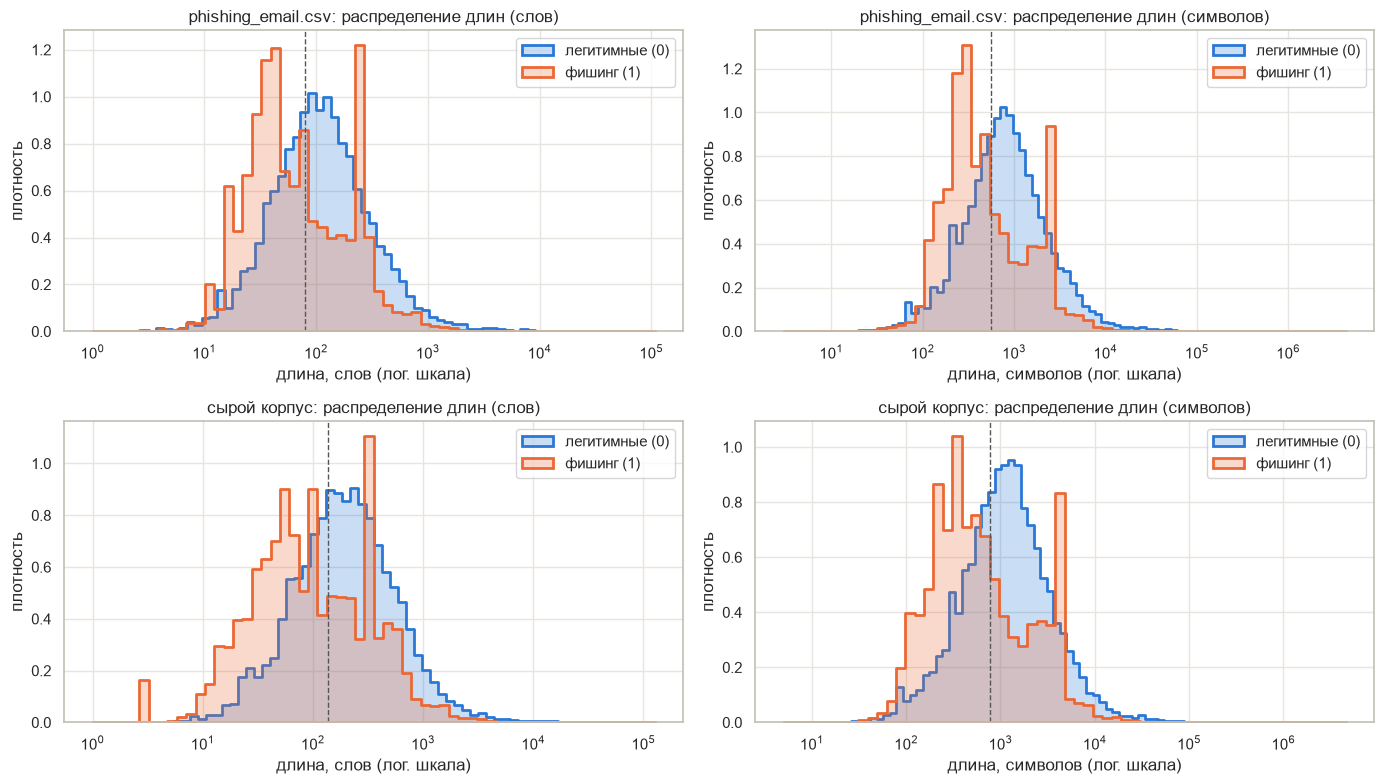

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for row, (frame, title) in enumerate([(train_df, "phishing_email.csv"), (raw_train, "сырой корпус")]):
    for col, (feat, xlabel) in enumerate([("n_words", "длина, слов"), ("n_chars", "длина, символов")]):
        ax = axes[row, col]
        data = frame[frame[feat] > 0]
        for lbl in (0, 1):
            sns.histplot(data.loc[data[TARGET] == lbl, feat], ax=ax, log_scale=True, bins=60,
                         stat="density", element="step", fill=True, alpha=0.25, linewidth=2,
                         color=CLASS_COLORS[lbl], label=CLASS_NAMES[lbl])
        ax.axvline(data[feat].median(), color="#555", ls="--", lw=1)
        ax.set_title(f"{title}: распределение длин ({xlabel.split(', ')[1]})")
        ax.set_xlabel(xlabel + " (лог. шкала)")
        ax.set_ylabel("плотность")
        ax.legend()
plt.tight_layout()
plt.show()

**Стоп-слова.** Используем английский список NLTK (198 слов). Считаем частоты на целых буквенных словах `\b[a-z]+('[a-z]+)?\b` после приведения к нижнему регистру.

Доля стоп-слов среди токенов: сырой корпус = 34.9%, phishing_email.csv = 0.00%


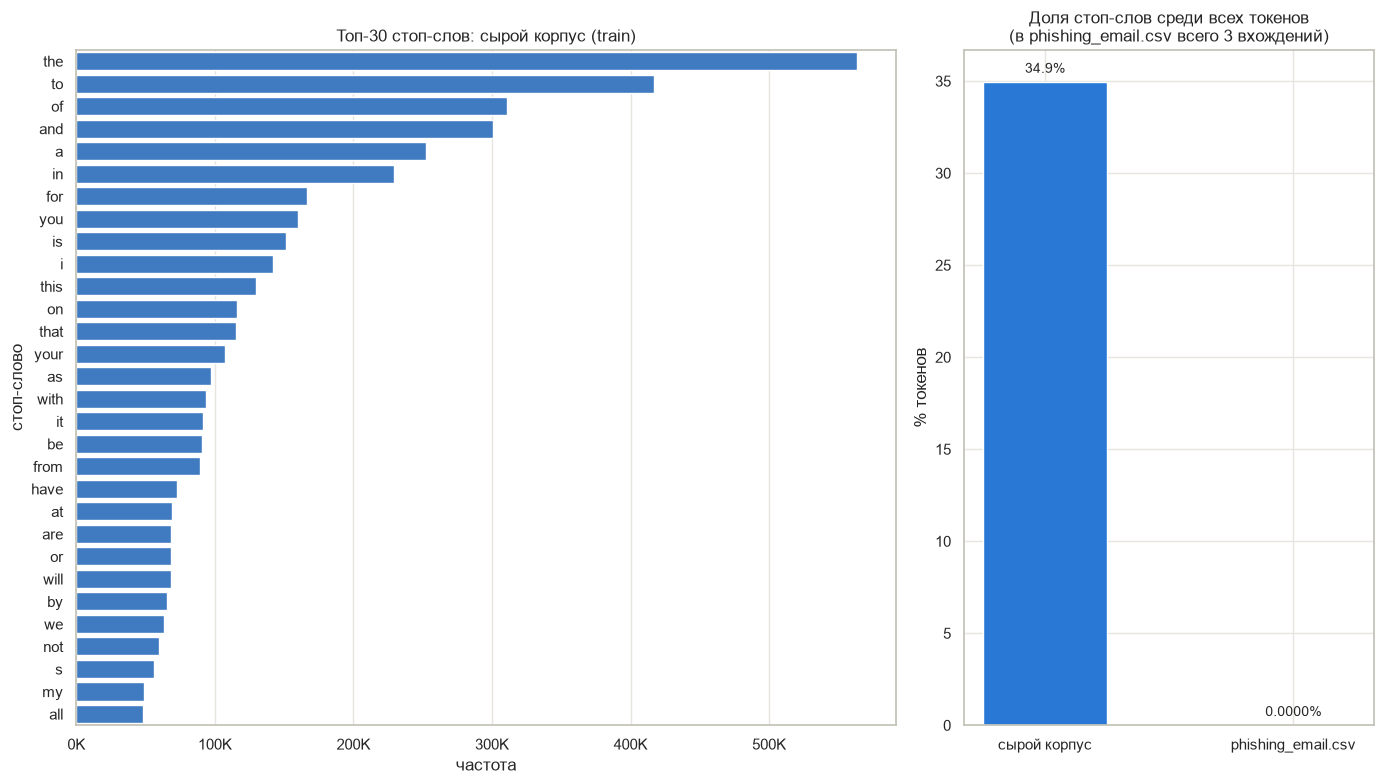

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
стоп-слово,the,to,of,and,a,in,for,you,is,i,...,at,are,or,will,by,we,not,s,my,all
частота (сырой),563286,416582,310605,300732,252156,229009,166336,159764,151383,141668,...,68975,68383,68213,68083,65155,63342,59501,56036,48895,47936
частота (phishing_email.csv),0,0,0,0,0,0,0,0,0,3,...,0,0,0,0,0,0,0,0,0,0


In [7]:
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))
WORD_RE = re.compile(r"\b[a-z]+(?:'[a-z]+)?\b")  # \b: не выдёргиваем "d" из "3d"

def token_counter(texts):
    cnt = Counter()
    for t in texts:
        cnt.update(WORD_RE.findall(t.lower()))
    return cnt

raw_cnt = token_counter(raw_train["text"])
comb_cnt = token_counter(train_df[TEXT])

def stop_share(cnt):
    total = sum(cnt.values())
    return sum(c for w, c in cnt.items() if w in STOP) / total

print(f"Доля стоп-слов среди токенов: сырой корпус = {stop_share(raw_cnt):.1%}, "
      f"phishing_email.csv = {stop_share(comb_cnt):.2%}")

top_stop = pd.DataFrame(
    [(w, c, comb_cnt.get(w, 0)) for w, c in raw_cnt.most_common() if w in STOP][:30],
    columns=["стоп-слово", "частота (сырой)", "частота (phishing_email.csv)"])
top_stop_comb = pd.DataFrame([(w, c) for w, c in comb_cnt.most_common() if w in STOP][:30],
                             columns=["стоп-слово", "частота"])

fig, axes = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={"width_ratios": [2, 1]})
sns.barplot(top_stop, y="стоп-слово", x="частота (сырой)", ax=axes[0], color=CLASS_COLORS[0])
axes[0].set_title("Топ-30 стоп-слов: сырой корпус (train)")
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1e3:.0f}K"))
axes[0].set_xlabel("частота")

shares = {"сырой корпус": stop_share(raw_cnt), "phishing_email.csv": stop_share(comb_cnt)}
axes[1].bar(list(shares), [v * 100 for v in shares.values()], color=CLASS_COLORS[0], width=0.5)
for x, v in enumerate(shares.values()):
    axes[1].text(x, v * 100 + 0.5, f"{v:.4%}" if v < 0.001 else f"{v:.1%}", ha="center", fontsize=10)
n_stop_comb = sum(c for w, c in comb_cnt.items() if w in STOP)
axes[1].set_title(f"Доля стоп-слов среди всех токенов\n(в phishing_email.csv всего {n_stop_comb} вхождений)")
axes[1].set_ylabel("% токенов")
plt.tight_layout()
plt.show()
top_stop.head(30).T

В основном корпусе какие стоп-слова всё же остались? Посмотрим топ уцелевших и на их контекст.

In [8]:
display(top_stop_comb.head(15).T)
survivors = top_stop_comb["стоп-слово"].head(5).tolist()
for w in survivors:
    rx = re.compile(rf"\b{w}\b")
    for ex in train_df[TEXT].sample(5000, random_state=SEED):
        m = rx.search(ex)
        if m:
            print(f"{w!r}: ...{ex[max(0, m.start()-60):m.start()+60]}...")
            break

,0
стоп-слово,i
частота,3


### Выводы по EDA

* **Объём и баланс.** В train основного корпуса 65 661 документ (после удаления 1 пустого текста и 408 дубликатов). Классы почти сбалансированы: 52,2% фишинга и 47,8% легитимных писем. Стратификация сохранила пропорции в test с точностью до 0,1%.
* **Длины.** Средняя длина — 161,6 слова / 1 309 символов, медиана — 79 слов / 559 символов. Среднее вдвое больше медианы, потому что у распределения тяжёлый правый хвост (максимум — 107 710 слов). Поэтому гистограммы построены в лог-шкале.
* **Фишинговые письма короче**: медиана 55 слов против 106 у легитимных (в сыром корпусе — 89 против 190). Длина — сама по себе полезный признак для классификатора.
* **Пики на гистограмме фишинга** (≈250 слов, ≈2–3 тыс. символов) — это массовые рассылки по одному шаблону: фейковые «CNN Daily Top 10» из CEAS, рассылки с хэшем вместо имени. Точные дубликаты мы удалили, а почти-дубликаты с разными URL/хэшами остались.
* **Сырой корпус в 1,7 раза длиннее** по словам (280 против 162). Разница почти целиком состоит из стоп-слов: в сыром корпусе они дают **34,9%** всех токенов (`the`, `to`, `of`, `and`, `a`, …).
* **В `phishing_email.csv` стоп-слов нет**: на 9,5 млн токенов train нашлось ровно 3 вхождения стоп-слова (`i`). Это доказывает, что авторы датасета удалили стоп-слова. Для классификации это скорее плюс (меньше шума), а для языковой модели — серьёзное ограничение: n-граммы строятся по «телеграфному» тексту из одних знаменательных слов (см. п. 7–9).

## 3. Анализ специфического шума

Для каждого типа шума задаём регулярное выражение-детектор и считаем долю документов train, в которых он встречается (отдельно по классам и по корпусам).

In [9]:
NOISE = {
    "HTML-теги":            r"</?(?:html|head|body|div|span|p|br|a|font|table|tr|td|img|b|i|u|center|style|script)\b[^<>]{0,300}>",
    "HTML-сущности":        r"&(?:#\d{1,6}|#x[0-9a-fA-F]{1,6}|[a-zA-Z]{2,8});",
    "quoted-printable":     r"=[0-9A-F]{2}|=\r?\n",
    "URL":                  r"(?:https?|ftp)://\S+|\bwww\.\S+",
    "URL «разреженный»":    r"\bhttps?\s:\s/\s/",
    "URL «склеенный»":      r"\b(?:https?|www)[a-z0-9]{4,}",
    "e-mail":               r"[\w.+\-]+@[\w\-]+(?:\.[\w\-]+)+",
    "e-mail «разреженный»": r"[\w.\-]+\s@\s[\w\-]+\s\.\s",
    "hex / хэши":           r"\b(?=[0-9a-fA-F]*\d)(?=[0-9a-fA-F]*[a-fA-F])[0-9a-fA-F]{8,}\b",
    "денежные суммы":       r"[$€£]\s?\d",
    "числа":                r"\b\d+\b",
    "растянутые слова":     r"([a-vx-zA-VX-Z])\1{2,}",
    "линии-разделители":    r"([=\-_*#~+.])(?:\s?\1){4,}",
    "не-ASCII символы":     r"[^\x00-\x7f]",
    "слова КАПСОМ":         r"\b[A-Z]{4,}\b",
}
NOISE_RE = {k: re.compile(v) for k, v in NOISE.items()}

def noise_report(texts, labels):
    rows = {}
    for name, rx in NOISE_RE.items():
        hit = texts.map(lambda t: rx.search(t) is not None)
        rows[name] = {"все": hit.mean(), CLASS_NAMES[0]: hit[labels == 0].mean(), CLASS_NAMES[1]: hit[labels == 1].mean()}
    return pd.DataFrame(rows).T

rep_raw = noise_report(raw_train["text"], raw_train[TARGET])
rep_comb = noise_report(train_df[TEXT], train_df[TARGET])
noise_tbl = pd.concat({"сырой корпус": rep_raw, "phishing_email.csv": rep_comb}, axis=1)
noise_tbl.style.format("{:.1%}").background_gradient(cmap="Blues", vmin=0, vmax=1)

In [10]:
def show_examples(texts, rx, k=4, width=50):
    out = []
    for t in texts:
        m = rx.search(t)
        if m:
            s, e = m.span()
            out.append(f"…{t[max(0, s-width//2):s]}⟦{t[s:e][:80]}⟧{t[e:e+width//2]}…".replace("\n", "⏎"))
        if len(out) == k:
            break
    return out

sample_raw = raw_train["text"].sample(20000, random_state=SEED)
sample_comb = train_df[TEXT].sample(20000, random_state=SEED)
for name, rx in NOISE_RE.items():
    print(f"=== {name}")
    for corpus, texts in [("сырой", sample_raw), ("основной", sample_comb)]:
        for ex in show_examples(texts, rx, k=2):
            print(f"  [{corpus}] {ex}")

=== HTML-теги
  [сырой] …_ Mail envoyer depuis le ⟦<a href="http://adi90.baoo.org>⟧Le Site de Adrien Webmast…
  [сырой] …0.99; '<!--':     0.99; '⟦</b>⟧': 0.99; '': 0.99; '': 0.…
=== HTML-сущности
  [сырой] …saction of this⏎nature, ⏎⟦&nbsp;⟧⏎My father (Late) DR Abdu…
  [сырой] …ying to score a goal[6]. ⟦&#8220;⟧As the best and the ⏎brig…
=== quoted-printable
  [сырой] …=========================⟦=⏎⟧⏎This is going to brief b…
  [сырой] …tp://cgi.cnn.com/m/clik?e⟦=59⟧be455986b13e5af5611e10fe7…
=== URL
  [сырой] …--Check it out...Photos: ⟦http://michling.myphotomax.com⟧ | Videos: http://maxcast…
  [сырой] …1. MOM PARTIES AT A CLUB ⟦http://www.cnn.com/video/partners/email/index.html?url=/video/crime/2008/08/05/n⟧ Nancy Grace has new phot…


=== URL «разреженный»
⏎web : ⟦http : / /⟧ hsb . baylor . edu / htm…
⏎…


=== URL «склеенный»
⏎click here to c…
  [сырой] …                  http://⟦www2006⟧.org/⏎⏎               May…
  [основной] …scom options visit group ⟦httpgroupsgooglecomgrouppownceapihlen⟧ wed 06 aug 2008 111221 0…
  [основной] … patras greece july 2008 ⟦httpwwwcsclivacukmjwmochart⟧ introduction model check…
=== e-mail
  [сырой] …POSAL,⏎⏎E-Mail, Address, ⟦hellenshakashaka@netscape.net⟧⏎⏎⏎Dear Friend⏎⏎⏎You may …
  [сырой] …ore info.Bill Michling / ⟦ydpu@mespn.com⟧ / Phone: 214-616-9566, H…


=== e-mail «разреженный»
⏎web : http : / / hsb…
  [сырой] …+ 1 914 747-1326 email : ⟦mouton @ degruyter . ⟧de this and further publi…


=== hex / хэши
  [сырой] …p://cgi.cnn.com/m/clik?e=⟦f96b5baa494132853167d05b69b7719f⟧@gvc.ceas-challenge.cc&l=…
  [сырой] …ADLE,�SK8�3JU,�U.K. PGP:�⟦2C15F1A9⟧������Fingerprint:�73�6D�…
  [основной] …rhillsmcmenaminscom dear ⟦8b041062bcf7766253bcd0284e2df718⟧ summer exact time take b…
  [основной] …ara staggerinwindit dear ⟦ebcdc70dbf44687d51890265054ca029⟧ summer great time take w…
=== денежные суммы
  [сырой] … to deposit the sum of US⟦$3⟧0 Million (thirty million…
  [сырой] …dm 428 , - / approx . us ⟦$ 2⟧68 . 00 isbn 3-11 - 01490…
=== числа
  [сырой] …to deposit the sum of US$⟦30⟧ Million (thirty million …
  [сырой] … ydpu@mespn.com / Phone: ⟦214⟧-616-9566, Home: 214-764-…
  [основной] …ing users belong set mar ⟦17⟧ 722 pm leah culver wrote…
  [основной] … com jane sales dept icq ⟦339616524⟧ please click away forour…
=== растянутые слова
  [сырой] …  Cable News Network LP, ⟦LLL⟧P.                       …
  [сырой] … It could as well use A, ⟦AAAA⟧, NS, TXR, RP (FWIW), etc…
  [основной

### Выводы по шуму

**Сырой корпус** — шум типичен для e-mail-домена (доля документов train):
1. **URL** — 39,7% документов. Ещё 8,0% содержат «разреженные» URL вида `http : / / www . enron . com`: файлы Enron и Ling были токенизированы через пробел. В фишинге URL встречаются чуть чаще (40,6% против 38,6%).
2. **E-mail-адреса** — 22,0% (плюс 9,8% «разреженных» `john @ enron . com`). У легитимных писем их больше (29,7%) за счёт подписей и списков рассылки.
3. **Quoted-printable** (`=3D`, `=20`, мягкий перенос `=⏎`) — 7,4%: артефакт MIME-кодирования.
4. **Hex-строки / хэши** — 5,2%, причём в фишинге вдвое чаще (7,0% против 3,3%): трекинговые идентификаторы и «персонализация» вида `Dear 8b041062bcf7…`.
5. **Денежные суммы** — 14,2% (фишинг 18,2% против 9,9%): `US$30 Million`.
6. **Линии-разделители** (`=====`, `- - - -`, `____`) — 29,6%; **не-ASCII** (битая кодировка `�`, `\xa0`, `©`) — 10,0%; **растянутые слова** (`meeeet`) — 11,9%; **КАПС** — 29,4%.

**HTML отсутствует** — это доказано: тегов 0,0% (на весь сырой train 43 совпадения, да и те внутри кода и цитат), сущностей 0,1%. HTML-разметку из писем вычистили ещё при сборке датасета.

**`phishing_email.csv`** — часть шума уже удалили авторы, но появился новый:
* **Доказано отсутствие** (0,0%) HTML, сущностей, quoted-printable, нормальных URL и e-mail, денежных сумм, КАПСА и стоп-слов: регистр понижен, пунктуация удалена.
* **Новый шум — «склеенные» URL** (`httpwwwcnncomvideopartners…`) в 39,5% документов. Удаление пунктуации превратило каждый URL в уникальный длинный «токен», раздувающий словарь. Так же склеились e-mail (`ricklinuxmafiacom`) — их уже нельзя надёжно отличить от слов.
* Остались числа (94,2%), hex-хэши (2,4%), растянутые слова (13,5%), подчёркивания-разделители (10,0%) и не-ASCII (3,4%).

## 4. Конвейер очистки на регулярных выражениях

Каждый тип шума обрабатывается **своим** правилом; порядок правил важен (например, URL и e-mail нужно заменить до замены чисел, иначе `http://site.com/2008/` развалится на части, а hex-хэш — до чисел, иначе от него останутся обрывки).

Решения о замене/удалении приняты с учётом задачи (детекция фишинга): URL, e-mail, хэши, суммы денег и числа — **значимые сигналы** фишинга, поэтому они не вырезаются, а заменяются на специальные токены `[URL]`, `[EMAIL]`, `[HEX]`, `[MONEY]`, `[NUM]`. Технические артефакты (HTML, quoted-printable, разделители, не-ASCII) смысла не несут и удаляются.

In [11]:
TLD = r"(?:com|net|org|edu|gov|mil|info|biz|de|uk|ru|fr|nl|au|ca|us|jp|cn|it|ch|se|io)"
SPECIAL_TOKENS = ["[URL]", "[EMAIL]", "[HEX]", "[MONEY]", "[NUM]"]
BOS, EOS, UNK = "<s>", "</s>", "[UNK]"

# (имя правила, регулярное выражение, замена). Правило lowercase — не regex, а смена регистра.
CLEANING_RULES = [
    # --- технические артефакты почтового формата ---
    ("qp_softbreak", re.compile(r"=\r?\n"), ""),                       # мягкий перенос quoted-printable
    ("qp_code",      re.compile(r"=[0-9A-F]{2}"), " "),                # =3D, =20 и т.п.
    ("html_block",   re.compile(r"<(script|style)\b.*?</\1\s*>", re.S | re.I), " "),
    ("html_tag",     re.compile(r"</?[a-zA-Z][a-zA-Z0-9]*(?:\s[^<>]{0,500})?/?>"), " "),
    ("html_entity",  re.compile(r"&(?:#\d{1,6}|#x[0-9a-fA-F]{1,6}|[a-zA-Z]{2,8});"),
                     lambda m: " " + html.unescape(m.group(0)) + " "),
    ("lowercase",    None, None),
    # --- сущности, значимые для фишинга -> специальные токены ---
    ("url",          re.compile(r"(?:https?|ftp)://\S+|\bwww\.\S+"), " [URL] "),
    ("url_spaced",   re.compile(r"\b(?:https?\s?:\s?/\s?/\s?|www\s\.\s)(?:[\w\-]+\s?\.\s?)*" + TLD +
                                r"\b(?:\s?/\s?[\w\-.~%?=&]+)*"), " [URL] "),
    ("url_glued",    re.compile(r"\b(?:https?|www)[a-z0-9]{4,}"), " [URL] "),
    ("email",        re.compile(r"[\w.+\-]+@[\w\-]+(?:\.[\w\-]+)+"), " [EMAIL] "),
    ("email_spaced", re.compile(r"[\w.\-]+\s@\s[\w\-]+(?:\s\.\s[\w\-]+)+"), " [EMAIL] "),
    # --- графический мусор: убираем ДО чисел, т.к. он может «приклеивать» цифры к словам ---
    ("separators",   re.compile(r"([=\-_*#~+.!?<>|/])(?:\s?\1){2,}"), " "),   # ====, - - - -, ____
    ("underscore",   re.compile(r"_+"), " "),                         # _important_, wng_qn
    ("non_ascii",    re.compile(r"[^\x00-\x7f]+"), " "),
    # --- оставшиеся значимые сущности ---
    ("hex",          re.compile(r"\b(?=[0-9a-f]*\d)(?=[0-9a-f]*[a-f])[0-9a-f]{8,}\b"), " [HEX] "),
    ("money",        re.compile(r"[$€£]\s?\d+(?:\s?[.,]\s?\d+)*"), " [MONEY] "),
    ("num",          re.compile(r"\b\d+(?:[.,:/\-]\d+)*\b"), " [NUM] "),
    ("collapse_special", re.compile(r"(\[(?:URL|EMAIL|HEX|MONEY|NUM)\])(?:\s+\1)+"), r"\1"),
    # --- нормализация «шумного» написания ---
    ("elongated",    re.compile(r"([a-z])\1{2,}"), r"\1\1"),          # meeeeet -> meet
]
# финальная токенизация: спец-токены | слова/числа (с апострофом внутри слова);
# всё остальное (одиночная пунктуация, подчёркивания) отбрасывается
TOKEN_RE = re.compile(r"\[(?:URL|EMAIL|HEX|MONEY|NUM)\]|[a-z0-9]+(?:'[a-z]+)?")


def clean_text(text: str, stats: Counter | None = None) -> str:
    for name, rx, repl in CLEANING_RULES:
        if name == "lowercase":
            text = text.lower()
            continue
        if stats is not None:
            text, n = rx.subn(repl, text)
            stats[name] += n
        else:
            text = rx.sub(repl, text)
    return f"{BOS} " + " ".join(TOKEN_RE.findall(text)) + f" {EOS}"


tests = [
    "Visit http://www.paypal-secure.com/login?id=42 NOW!!!",
    "see http : / / www . enron . com / docs / a . html thanks",
    "mail john @ enron . com today",
    "Dear d2edaed0a9e91129f704d4a6b68ba62b, pay $ 1,000.50 or $5 at 12:30 on 05/29/2001",
    "hellooooo meeeeet <b>bold</b> &amp; <a href=\"x\">link</a> =3D click=\nhere",
    "=================== caf\u00e9 \u00a9 2008 ------ _important_",
    "glued url httpwwwmilddonecom and 2001 05 29 08 37",
]
for t in tests:
    print(f"{t!r}\n   -> {clean_text(t)}")

'Visit http://www.paypal-secure.com/login?id=42 NOW!!!'
   -> <s> visit [URL] now </s>
'see http : / / www . enron . com / docs / a . html thanks'
   -> <s> see [URL] html thanks </s>
'mail john @ enron . com today'
   -> <s> mail [EMAIL] today </s>
'Dear d2edaed0a9e91129f704d4a6b68ba62b, pay $ 1,000.50 or $5 at 12:30 on 05/29/2001'
   -> <s> dear [HEX] pay [MONEY] or [MONEY] at [NUM] on [NUM] </s>
'hellooooo meeeeet <b>bold</b> &amp; <a href="x">link</a> =3D click=\nhere'
   -> <s> helloo meet bold link clickhere </s>
'=================== café © 2008 ------ _important_'
   -> <s> caf [NUM] important </s>
'glued url httpwwwmilddonecom and 2001 05 29 08 37'
   -> <s> glued url [URL] and [NUM] </s>


In [12]:
t0 = time.time()
rule_stats_comb, rule_stats_raw = Counter(), Counter()
train_df["clean"] = [clean_text(t, rule_stats_comb) for t in train_df[TEXT]]
test_df["clean"] = [clean_text(t) for t in test_df[TEXT]]
raw_train["clean"] = [clean_text(t, rule_stats_raw) for t in raw_train["text"]]
raw_test["clean"] = [clean_text(t) for t in raw_test["text"]]
print(f"Очистка всех 4 выборок: {time.time() - t0:.0f} c")

pd.DataFrame({"phishing_email.csv": rule_stats_comb, "сырой корпус": rule_stats_raw}).fillna(0).astype(int) \
    .loc[[r[0] for r in CLEANING_RULES if r[0] != "lowercase"]].rename_axis("правило: число срабатываний (train)")

Очистка всех 4 выборок: 67 c


,phishing_email.csv,сырой корпус
правило: число срабатываний (train),,
qp_softbreak,0,6080
qp_code,0,64651
html_block,0,0
html_tag,0,43
html_entity,0,250
url,0,128948
url_spaced,0,8050
url_glued,126728,29
email,0,76780


In [13]:
for frame, col in [(train_df, TEXT), (raw_train, "text")]:
    for i in frame.sample(2, random_state=7).index:
        print("ДО:   ", repr(frame.at[i, col][:400]))
        print("ПОСЛЕ:", frame.at[i, "clean"][:400], "\n")

ДО:    'hang seng bank ltd mr wang qin hang seng bank ltd des voeux rd branch central hong kong hong kong email wng _ qn yahoo com let start introducing mr wang qin credit officer hang seng bank ltd concealed business suggestion u iraqi war client general ibrahim moussa iraqi forces also business man made numbered fixed deposit 18 calendar months value twenty six million five hundred thousand united state'
ПОСЛЕ: <s> hang seng bank ltd mr wang qin hang seng bank ltd des voeux rd branch central hong kong hong kong email wng qn yahoo com let start introducing mr wang qin credit officer hang seng bank ltd concealed business suggestion u iraqi war client general ibrahim moussa iraqi forces also business man made numbered fixed deposit [NUM] calendar months value twenty six million five hundred thousand united  

ДО:    'jon zeezeircomnet hey given old toshiba cs100 earliest pentium 400mb hd floppy drive got win31 funny see gon na cleared soon stop messing wondering could anyone advise os w

Проверка конвейера: повторно прогоняем детекторы шума по очищенным текстам (спец-токены `[URL]`, `[NUM]`, … временно вырезаем, иначе детектор КАПСА сработает на них самих) — все доли должны стать нулевыми или близкими к нулю.

In [14]:
SPECIAL_RE = re.compile(r"\[(?:URL|EMAIL|HEX|MONEY|NUM)\]")
after = pd.concat({
    "phishing_email.csv": noise_report(train_df["clean"].str.replace(SPECIAL_RE, " ", regex=True), train_df[TARGET])["все"],
    "сырой корпус": noise_report(raw_train["clean"].str.replace(SPECIAL_RE, " ", regex=True), raw_train[TARGET])["все"],
}, axis=1)
after.style.format("{:.2%}")

,phishing_email.csv,сырой корпус
HTML-теги,0.00%,0.00%
HTML-сущности,0.00%,0.00%
quoted-printable,0.00%,0.00%
URL,0.00%,0.00%
URL «разреженный»,0.00%,0.00%
URL «склеенный»,0.02%,0.00%
e-mail,0.00%,0.00%
e-mail «разреженный»,0.00%,0.00%
hex / хэши,0.00%,0.00%
денежные суммы,0.00%,0.00%


Насколько специальные токены различают классы? Среднее число вхождений на документ:

In [15]:
spec = {}
for frame, name in [(train_df, "phishing_email.csv"), (raw_train, "сырой корпус")]:
    for tok in SPECIAL_TOKENS:
        cnt = frame["clean"].str.count(re.escape(tok))
        spec[(name, tok)] = cnt.groupby(frame[TARGET]).mean().rename(CLASS_NAMES)
pd.DataFrame(spec).T.round(2)

label                       легитимные (0)  фишинг (1)
phishing_email.csv [URL]              1.59        2.09
                   [EMAIL]            0.00        0.00
                   [HEX]              0.07        0.09
                   [MONEY]            0.00        0.00
                   [NUM]             11.01        7.42
сырой корпус       [URL]              1.87        2.23
                   [EMAIL]            1.14        1.63
                   [HEX]              0.10        0.11
                   [MONEY]            0.61        0.66
                   [NUM]             15.73        7.07

### Выводы по очистке

* После конвейера все детекторы шума на обоих корпусах показывают **0,00%**; единственное исключение — 0,02% «склеенных URL» с короткими хвостами. Каждое правило проверено на модельных примерах.
* **Порядок правил критичен.** URL и e-mail заменяются до чисел, иначе `http://cnn.com/2008/08/05` развалился бы на `[NUM]`. Подчёркивания и не-ASCII удаляются до чисел: при первом прогоне правило `[NUM]` стояло раньше, и `_2008` превращалось в отдельное число уже после него — повторная проверка это поймала.
* Схлопывание подряд идущих спец-токенов (`[NUM] [NUM] [NUM]` → `[NUM]`) превращает даты вида `05 29 2001 08 37` в один токен. Это нужно для языковой модели: иначе она выучила бы бессмысленные цепочки `[NUM]`.
* **Спец-токены несут сигнал о классе.** В фишинге больше `[URL]` (2,09 против 1,59 на документ) и `[EMAIL]` (1,63 против 1,14 в сыром корпусе). В легитимных — заметно больше `[NUM]` (11,0 против 7,4): деловая переписка Enron насыщена объёмами, датами и номерами сделок. Поэтому сущности заменяются на токены, а не вырезаются.
* **Ограничения**: склеенные e-mail и домены без `http` (`godaddycom`), разбивка по буквам (`o n l i n e u n i v e r s i t y`) и артефакт `nan` (пустые subject, которые авторы датасета превратили в строку) остаются. Их надёжное распознавание требует словаря доменов или сегментации слов.

## 5. Сравнительная нормализация: стемминг vs лемматизация

Работаем с токенами очищенного train основного корпуса (без `<s>`, `</s>` и спец-токенов).
* **Стемминг:** Porter, Snowball (Porter2) и агрессивный Lancaster — для сравнения.
* **Лемматизация:** WordNet-лемматизатор (а) без POS (всё считается существительным), (б) с POS-тегами из контекстного тэггера NLTK (averaged perceptron).

Чтобы не нормализовать 10+ млн токенов по одному, нормализуем **словарь уникальных форм** (стеммер детерминирован, результат кэшируется), а для лемматизации с POS — уникальные пары (слово, POS).

In [16]:
from nltk.stem import PorterStemmer, SnowballStemmer, LancasterStemmer, WordNetLemmatizer
from nltk.corpus import wordnet as wn

def words_of(clean):
    return [t for t in clean.split()[1:-1] if not t.startswith("[")]

train_tokens = [words_of(c) for c in train_df["clean"]]
test_tokens = [words_of(c) for c in test_df["clean"]]
word_freq = Counter(t for doc in train_tokens for t in doc)
vocab = list(word_freq)
print(f"Токенов в train: {sum(word_freq.values()):,}, уникальных форм: {len(vocab):,}")

stemmers = {"Porter": PorterStemmer(), "Snowball": SnowballStemmer("english"), "Lancaster": LancasterStemmer()}
stem_maps = {name: {w: st.stem(w) for w in vocab} for name, st in stemmers.items()}

lemmatizer = WordNetLemmatizer()
lemma_nopos = {w: lemmatizer.lemmatize(w) for w in vocab}

Токенов в train: 9,464,838, уникальных форм: 436,839


In [17]:
def wn_pos(tag):
    return {"J": wn.ADJ, "V": wn.VERB, "R": wn.ADV}.get(tag[0], wn.NOUN)

t0 = time.time()
tagged = nltk.pos_tag_sents(train_tokens)
pair_freq = Counter((w, wn_pos(tag)) for sent in tagged for w, tag in sent)
del tagged
lemma_pos = {pair: lemmatizer.lemmatize(*pair) for pair in pair_freq}
print(f"POS-разметка и лемматизация: {time.time() - t0:.0f} c, уникальных пар (слово, POS): {len(pair_freq):,}")

POS-разметка и лемматизация: 205 c, уникальных пар (слово, POS): 539,582


In [18]:
def oov_rate(train_set, test_docs, f):
    toks = [f(t) for doc in test_docs for t in doc]
    return sum(t not in train_set for t in toks) / len(toks)

norm_rows = {"без нормализации": (set(vocab), lambda w: w)}
for name, st in stemmers.items():
    m = stem_maps[name]
    norm_rows[f"стемминг {name}"] = (set(m.values()), st.stem)
norm_rows["лемматизация WordNet (без POS)"] = (set(lemma_nopos.values()), lemmatizer.lemmatize)
norm_rows["лемматизация WordNet + POS"] = (set(lemma_pos.values()), None)

base = len(vocab)
norm_tbl = pd.DataFrame({
    name: {"размер словаря": len(s), "сжатие словаря": 1 - len(s) / base,
           "OOV на test": oov_rate(s, test_tokens, f) if f else np.nan}
    for name, (s, f) in norm_rows.items()
}).T
norm_tbl.style.format({"размер словаря": "{:,.0f}", "сжатие словаря": "{:.1%}", "OOV на test": "{:.2%}"}, na_rep="—")

,размер словаря,сжатие словаря,OOV на test
без нормализации,"436,839",0.0%,2.84%
стемминг Porter,"395,256",9.5%,2.62%
стемминг Snowball,"395,926",9.4%,2.62%
стемминг Lancaster,"371,715",14.9%,2.46%
лемматизация WordNet (без POS),"426,777",2.3%,2.80%
лемматизация WordNet + POS,"425,764",2.5%,—


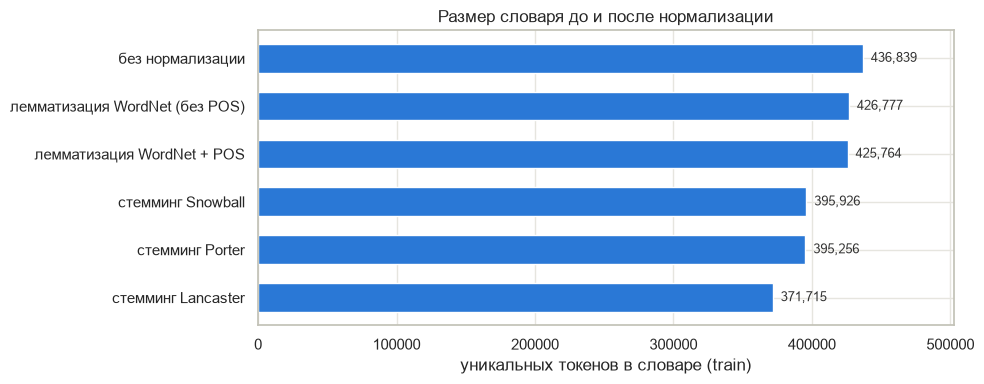

In [19]:
fig, ax = plt.subplots(figsize=(10, 4))
sizes = norm_tbl["размер словаря"].sort_values()
ax.barh(sizes.index, sizes.values, color=CLASS_COLORS[0], height=0.6)
for y, v in enumerate(sizes.values):
    ax.text(v, y, f"  {v:,.0f}", va="center", fontsize=9, color="#333")
ax.set_xlabel("уникальных токенов в словаре (train)")
ax.set_title("Размер словаря до и после нормализации")
ax.set_xlim(0, sizes.max() * 1.15)
plt.tight_layout()
plt.show()

Качественное сравнение: что именно склеивают методы.

In [20]:
groups = defaultdict(list)
for w, s in stem_maps["Porter"].items():
    groups[s].append(w)
top_groups = sorted(groups.items(), key=lambda kv: -sum(word_freq[w] for w in kv[1]))
print("Крупные группы Porter (стем: формы):")
for s, ws in [g for g in top_groups if len(g[1]) >= 4][:8]:
    print(f"  {s:12s} <- {sorted(ws, key=lambda w: -word_freq[w])[:8]}")

common = [w for w, _ in word_freq.most_common(3000)]
cmp_words = ["companies", "university", "universe", "business", "information", "receiving", "was", "better",
             "running", "meeting", "accounts", "verify", "verification", "generously", "organization", "news"]
pos_of = {}
for (w, p), c in pair_freq.items():
    if c > pos_of.get(w, ("", 0))[1]:
        pos_of[w] = (p, c)
pd.DataFrame([{"слово": w, "Porter": stem_maps["Porter"].get(w, PorterStemmer().stem(w)),
               "Snowball": stem_maps["Snowball"].get(w, ""), "Lancaster": stem_maps["Lancaster"].get(w, ""),
               "лемма (без POS)": lemmatizer.lemmatize(w),
               "лемма (+POS)": lemmatizer.lemmatize(w, pos_of[w][0]) if w in pos_of else "—",
               "частота": word_freq.get(w, 0)} for w in cmp_words])

Крупные группы Porter (стем: формы):
  use          <- ['use', 'using', 'used', 'uses', 'useful', 'usefulness', 'usefully', 'useing']
  email        <- ['email', 'emails', 'emailing', 'emailed', 'emailer', 'emailers', 'emaile', 'emailings']
  pleas        <- ['please', 'pleased', 'pleasing', 'pleases']
  compani      <- ['company', 'companies', 'companys', 'companied']
  time         <- ['time', 'times', 'timing', 'timely', 'timed', 'timings']
  inform       <- ['information', 'inform', 'informed', 'informations', 'informal', 'informational', 'informative', 'informing']
  mail         <- ['mail', 'mailing', 'mailings', 'mails', 'mailed', 'maile']
  messag       <- ['message', 'messages', 'messaging', 'messag', 'messager']


,слово,Porter,Snowball,Lancaster,лемма (без POS),лемма (+POS),частота
0,companies,compani,compani,company,company,company,5311
1,university,univers,univers,univers,university,university,13706
2,universe,univers,univers,univers,universe,universe,179
3,business,busi,busi,busy,business,business,15824
4,information,inform,inform,inform,information,information,22408
5,receiving,receiv,receiv,receiv,receiving,receive,3592
6,was,wa,was,was,wa,be,2
7,better,better,better,bet,better,well,4937
8,running,run,run,run,running,run,3083
9,meeting,meet,meet,meet,meeting,meeting,4581


In [21]:
spam_words = [w for w in ["viagra", "v1agra", "vlagra", "viagr", "via6ra", "cialis", "c1alis", "pharmacy",
                          "meds", "mortgage", "porn"] if w in word_freq]
pd.DataFrame([{"форма": w, "частота": word_freq[w], "Porter": stem_maps["Porter"][w],
               "лемма": lemma_nopos[w]} for w in spam_words])

,форма,частота,Porter,лемма
0,viagra,1557,viagra,viagra
1,vlagra,106,vlagra,vlagra
2,viagr,32,viagr,viagr
3,cialis,822,ciali,cialis
4,pharmacy,831,pharmaci,pharmacy
5,meds,896,med,med
6,mortgage,865,mortgag,mortgage
7,porn,293,porn,porn


### Выводы по нормализации

| метод | словарь | сжатие | OOV на test |
|---|---|---|---|
| без нормализации | 436 839 | — | 2,84% |
| Porter / Snowball | ≈395 300 / 395 900 | 9,5% / 9,4% | 2,62% |
| Lancaster | 371 715 | 14,9% | 2,46% |
| WordNet (без POS / +POS) | 426 777 / 425 764 | 2,3% / 2,5% | 2,80% |

* **Почему сжатие небольшое.** Словарь этого корпуса — длинный хвост «не-слов»: имена, склеенные URL и домены, хэши, обфускации, опечатки, иностранные тексты. Ни стеммер, ни лемматизатор их не сократят. Лемматизатор меняет только слова, известные WordNet, поэтому сжатие у него минимальное. Стеммер применяет суффиксные правила к любой строке и сжимает сильнее, в том числе мусор.
* **Стемминг склеивает лишнее.** `university`/`universe` → `univers`, `generously` → `gener`, `organization` → `organ`. У Lancaster ещё хуже: `business` → `busy`, `news` → `new`, `verify` → `ver`. Основы получаются не-словами (`compani`, `pleas`), но для классификатора это неважно.
* **Лемматизация даёт настоящие слова, но требует POS.** Без POS `was` → `wa`, а `receiving` не меняется. С POS — `be` и `receive`, а `better` → `well` (тег наречия). Цена — около 200 с на POS-разметку против долей секунды у стеммера. В нашем корпусе нет стоп-слов, поэтому контекстная POS-разметка ещё и менее точна.
* **Обфускации** (`vlagra`, `viagr`) не обрабатывает ни один метод: с ними справляется только поиск по строковому расстоянию (п. 6).

**Применимость.** Для детекции фишинга мешком слов / TF-IDF разумен **Snowball-стемминг**: он дешёвый, сжимает словарь в 4 раза сильнее лемматизации и снижает OOV, а нечитаемость основ модели не мешает. Lancaster слишком агрессивен: он склеивает разные по смыслу слова. **Лемматизация** оправдана там, где важна интерпретируемость признаков или текст генерируется (языковая модель, суммаризация). Для языковой модели в п. 7 мы не нормализуем текст вовсе, чтобы генерировать реальные словоформы.

## 6. Поиск опечаток через расстояние Левенштейна

Реализация — классическое динамическое программирование (Вагнер–Фишер) с двумя оптимизациями:
1. **Память O(min(|a|, |b|))**: хранится только предыдущая и текущая строка матрицы, а по столбцам идёт более короткое слово.
2. **Ранний выход по порогу** `max_dist`: если разница длин больше порога или минимум в текущей строке уже превышает порог, дальше считать бессмысленно (значения в строках DP не убывают).

In [22]:
def levenshtein(a: str, b: str, max_dist: int | None = None) -> int:
    """Расстояние Левенштейна (вставка/удаление/замена = 1). Память O(min(|a|, |b|)).
    При заданном max_dist возвращает max_dist + 1, если расстояние заведомо больше порога."""
    if len(a) < len(b):
        a, b = b, a                      # b — более короткая строка, по ней строим строку DP
    if max_dist is not None and len(a) - len(b) > max_dist:
        return max_dist + 1
    prev = list(range(len(b) + 1))       # D[i-1][*]
    for i, ca in enumerate(a, 1):
        cur = [i] + [0] * len(b)         # D[i][*]
        for j, cb in enumerate(b, 1):
            cur[j] = min(prev[j] + 1,            # удаление
                         cur[j - 1] + 1,         # вставка
                         prev[j - 1] + (ca != cb))  # замена / совпадение
        if max_dist is not None and min(cur) > max_dist:
            return max_dist + 1
        prev = cur
    if max_dist is not None:
        return min(prev[-1], max_dist + 1)
    return prev[-1]


def levenshtein_full_matrix(a, b):
    """Эталон для проверки: полная матрица (n+1)x(m+1)."""
    D = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]
    for i in range(len(a) + 1):
        D[i][0] = i
    for j in range(len(b) + 1):
        D[0][j] = j
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            D[i][j] = min(D[i-1][j] + 1, D[i][j-1] + 1, D[i-1][j-1] + (a[i-1] != b[j-1]))
    return D[-1][-1]


for a, b, exp in [("kitten", "sitting", 3), ("flaw", "lawn", 2), ("", "abc", 3), ("paypal", "paypal", 0),
                  ("paypal", "paypa1", 1), ("account", "acount", 1), ("verify", "verfy", 1)]:
    assert levenshtein(a, b) == exp, (a, b)
rnd = random.Random(0)
for _ in range(2000):
    a = "".join(rnd.choices("abcd", k=rnd.randint(0, 8)))
    b = "".join(rnd.choices("abcd", k=rnd.randint(0, 8)))
    d = levenshtein_full_matrix(a, b)
    assert levenshtein(a, b) == d
    assert levenshtein(a, b, max_dist=2) == min(d, 3)
print("Все проверки пройдены")

Все проверки пройдены


**Поиск пар.** Перебор всех пар словаря (~10¹⁰ сравнений) нереален, поэтому:
* «эталонные» слова — частые (≥ 100 вхождений), буквенные, длина ≥ 4;
* «кандидаты в опечатки» — буквенные слова длины ≥ 4, встречающиеся ≥ 3 раз, но минимум в 50 раз реже эталона;
* порог расстояния зависит от длины: для слов короче 6 символов допускаем только 1 правку (две правки в 4–5-буквенном слове меняют до половины слова — `nine`→`time`, `palo`→`also`), для длинных — до 2;
* чтобы не сравнивать каждого кандидата со всеми эталонами, используем **индекс удалений** (идея SymSpell): у двух слов на расстоянии ≤ 2 обязательно найдётся общая строка, получаемая удалением ≤ 2 символов из каждого. Индекс лишь отбирает пары-кандидаты, а **расстояние для каждой пары считает наша функция `levenshtein`**.

In [23]:
def deletes(word, depth):
    out, frontier = {word}, {word}
    for _ in range(depth):
        frontier = {w[:i] + w[i+1:] for w in frontier for i in range(len(w))}
        out |= frontier
    return out

MAX_D, REF_MIN, VAR_MIN, RATIO = 2, 100, 3, 50
refs = [w for w, c in word_freq.items() if c >= REF_MIN and w.isalpha() and len(w) >= 4]
index = defaultdict(set)
for w in refs:
    for d in deletes(w, MAX_D):
        index[d].add(w)

t0 = time.time()
pairs, n_calls = [], 0
variants = [w for w, c in word_freq.items() if c >= VAR_MIN and w.isalpha() and len(w) >= 4]
for v in variants:
    fv = word_freq[v]
    cands = set()
    for d in deletes(v, MAX_D):
        cands |= index.get(d, set())
    best = None
    for r in cands:
        if r == v or word_freq[r] < RATIO * fv:
            continue
        n_calls += 1
        allowed = 1 if len(v) < 6 else MAX_D   # порог зависит от длины слова
        dist = levenshtein(v, r, max_dist=allowed)
        if dist <= allowed and (best is None or (dist, -word_freq[r]) < (best[1], -word_freq[best[0]])):
            best = (r, dist)
    if best:
        pairs.append({"вариант": v, "эталон": best[0], "расстояние": best[1],
                      "частота варианта": fv, "частота эталона": word_freq[best[0]]})
pairs = pd.DataFrame(pairs)
print(f"Эталонов: {len(refs):,}, кандидатов: {len(variants):,}, вызовов levenshtein: {n_calls:,}, "
      f"найдено пар: {len(pairs):,}, время: {time.time() - t0:.0f} c")

# Разделяем пары на «разные формы одного слова» (общая основа Porter) и опечатки/обфускации
porter = stemmers["Porter"]
pairs["тип"] = np.where(pairs["вариант"].map(porter.stem) == pairs["эталон"].map(porter.stem),
                        "словоформа", "опечатка / обфускация")
pairs["тип"].value_counts()

Эталонов: 8,078, кандидатов: 96,957, вызовов levenshtein: 612,144, найдено пар: 24,435, время: 6 c


тип
опечатка / обфускация    23147
словоформа                1288
Name: count, dtype: int64

Сначала — «наивный» топ без фильтрации: видно, что малое расстояние редактирования само по себе не означает опечатку.

In [24]:
for d in (1, 2):
    print(f"Наивный топ-10 пар с расстоянием {d} (по частоте варианта):")
    display(pairs[pairs["расстояние"] == d].sort_values("частота варианта", ascending=False).head(10).reset_index(drop=True))

Наивный топ-10 пар с расстоянием 1 (по частоте варианта):


,вариант,эталон,расстояние,частота варианта,частота эталона,тип
0,companys,company,1,435,23523,словоформа
1,lake,like,1,330,17900,опечатка / обфускация
2,informations,information,1,312,22408,словоформа
3,qmail,email,1,311,34494,опечатка / обфускация
4,piease,please,1,288,31868,опечатка / обфускация
5,lease,please,1,247,31868,опечатка / обфускация
6,wang,want,1,247,12947,опечатка / обфускация
7,subjects,subject,1,244,16470,словоформа
8,universite,university,1,229,13706,опечатка / обфускация
9,emai,email,1,229,34494,опечатка / обфускация


Наивный топ-10 пар с расстоянием 2 (по частоте варианта):


,вариант,эталон,расстояние,частота варианта,частота эталона,тип
0,detail,email,2,672,34494,опечатка / обфускация
1,listen,list,2,368,18413,опечатка / обфускация
2,webmail,email,2,361,34494,опечатка / обфускация
3,linked,like,2,355,17900,опечатка / обфускация
4,timely,time,2,327,24274,словоформа
5,compaq,company,2,314,23523,опечатка / обфускация
6,mainly,mail,2,275,14460,опечатка / обфускация
7,unlike,like,2,264,17900,опечатка / обфускация
8,seller,sender,2,263,18673,опечатка / обфускация
9,portal,total,2,261,17923,опечатка / обфускация


Многие «варианты» — это **самостоятельные слова** (`lake`/`like`, `lease`/`please`): малое расстояние редактирования между короткими словами — обычное дело. Поэтому добавляем словарный фильтр: опечаткой считаем только вариант, которого **нет в словаре** (WordNet + стоп-слова NLTK). Словоформы (`companys`, `informations`) WordNet тоже не знает — их помечаем отдельно по совпадению основы Porter.

In [25]:
def in_dictionary(w):
    return w in STOP or bool(wn.synsets(w)) or bool(wn.synsets(lemmatizer.lemmatize(w, "v")))

pairs["в словаре"] = pairs["вариант"].map(in_dictionary)
typos_all = pairs[~pairs["в словаре"]].sort_values("частота варианта", ascending=False)
print(f"Пар, где вариант отсутствует в словаре: {len(typos_all):,} из {len(pairs):,}")
for d in (1, 2):
    print(f"Топ-10 опечаток с расстоянием {d}:")
    display(typos_all[typos_all["расстояние"] == d].head(10).reset_index(drop=True)
            .drop(columns="в словаре"))

Пар, где вариант отсутствует в словаре: 14,566 из 24,435
Топ-10 опечаток с расстоянием 1:


,вариант,эталон,расстояние,частота варианта,частота эталона,тип
0,qmail,email,1,311,34494,опечатка / обфускация
1,piease,please,1,288,31868,опечатка / обфускация
2,wang,want,1,247,12947,опечатка / обфускация
3,emai,email,1,229,34494,опечатка / обфускация
4,universite,university,1,229,13706,опечатка / обфускация
5,universit,university,1,220,13706,опечатка / обфускация
6,ciick,click,1,166,11075,опечатка / обфускация
7,aiso,also,1,153,18035,опечатка / обфускация
8,miilion,million,1,149,9129,опечатка / обфускация
9,miliion,million,1,146,9129,опечатка / обфускация


Топ-10 опечаток с расстоянием 2:


,вариант,эталон,расстояние,частота варианта,частота эталона,тип
0,webmail,email,2,361,34494,опечатка / обфускация
1,compaq,company,2,314,23523,опечатка / обфускация
2,beleive,receive,2,194,10716,опечатка / обфускация
3,recieve,receive,2,180,10716,опечатка / обфускация
4,hettinga,settings,2,156,7880,опечатка / обфускация
5,maiings,mailing,2,149,8169,опечатка / обфускация
6,dupont,dont,2,144,9639,опечатка / обфускация
7,readme,read,2,128,8711,опечатка / обфускация
8,universitat,university,2,126,13706,опечатка / обфускация
9,benson,enron,2,122,42464,опечатка / обфускация


In [26]:
print("Топ-10 «настоящих» опечаток/обфускаций (вне словаря и основы Porter различаются):")
typos = typos_all[typos_all["тип"] != "словоформа"]
display(typos.head(10).reset_index(drop=True).drop(columns="в словаре"))

Топ-10 «настоящих» опечаток/обфускаций (вне словаря и основы Porter различаются):


,вариант,эталон,расстояние,частота варианта,частота эталона,тип
0,webmail,email,2,361,34494,опечатка / обфускация
1,compaq,company,2,314,23523,опечатка / обфускация
2,qmail,email,1,311,34494,опечатка / обфускация
3,piease,please,1,288,31868,опечатка / обфускация
4,wang,want,1,247,12947,опечатка / обфускация
5,emai,email,1,229,34494,опечатка / обфускация
6,universite,university,1,229,13706,опечатка / обфускация
7,universit,university,1,220,13706,опечатка / обфускация
8,beleive,receive,2,194,10716,опечатка / обфускация
9,recieve,receive,2,180,10716,опечатка / обфускация


In [27]:
def class_share(word):
    m = train_df["clean"].str.contains(rf"\b{re.escape(word)}\b")
    return train_df.loc[m, TARGET].mean()

check = typos.head(15).drop(columns="в словаре").copy()
check["доля фишинга (вариант)"] = check["вариант"].map(class_share).round(2)
check["доля фишинга (эталон)"] = check["эталон"].map(class_share).round(2)
check.reset_index(drop=True)

,вариант,эталон,расстояние,частота варианта,частота эталона,тип,доля фишинга (вариант),доля фишинга (эталон)
0,webmail,email,2,361,34494,опечатка / обфускация,0.80,0.59
1,compaq,company,2,314,23523,опечатка / обфускация,0.71,0.78
2,qmail,email,1,311,34494,опечатка / обфускация,0.31,0.59
3,piease,please,1,288,31868,опечатка / обфускация,1.00,0.46
4,wang,want,1,247,12947,опечатка / обфускация,0.21,0.48
5,emai,email,1,229,34494,опечатка / обфускация,0.98,0.59
6,universite,university,1,229,13706,опечатка / обфускация,0.00,0.05
7,universit,university,1,220,13706,опечатка / обфускация,0.02,0.05
8,beleive,receive,2,194,10716,опечатка / обфускация,0.74,0.78
9,recieve,receive,2,180,10716,опечатка / обфускация,0.82,0.78


### Выводы по поиску опечаток

* Реализация проверена: известные примеры (`kitten`/`sitting` = 3) и 2000 случайных пар сверены с эталоном на полной матрице, с порогом и без. Память — O(min(|a|,|b|)): хранятся две строки DP по более короткому слову.
* **Индекс удалений** сократил перебор с ~8 тыс. × 97 тыс. ≈ 780 млн пар до 612 тыс. вызовов `levenshtein`; поиск занял около 5 с.
* **Наивный топ показывает ловушку метода**: `lake`/`like`, `lease`/`please`, `detail`/`email`, `listen`/`list` — расстояние маленькое, но это разные слова. `companys`, `informations`, `subjects` — разные формы одного слова.
* **После словарного фильтра** остаются настоящие опечатки и обфускации:
  * **Визуальные замены `l` → `i`**: `piease`, `ciick`, `aiso`, `miilion`, `maiings`. Это типичный приём спамеров против фильтров по ключевым словам. Доля фишинга у таких форм — **100%** (у исходных слов — 16–82%). Найденные опечатки — почти идеальный признак фишинга.
  * **Обычные опечатки**: `emai` → `email` (98% фишинга), `recieve` → `receive`, `universit(e)` → `university` (последние — из франко- и немецкоязычных академических рассылок, 0% фишинга).
* **Ложные срабатывания** — имена собственные и бренды, которых нет в WordNet: `wang`/`want`, `compaq`/`company`, `qmail`/`email`, `dupont`/`dont`, `benson`/`enron`. Ещё `beleive` сопоставилось с `receive`, а не с `believe`: слово `believe` не прошло порог «эталон в 50 раз частотнее варианта». Значит, ранжировать кандидатов стоит не только по расстоянию, но и по частоте и вероятности замены (модель шумного канала).

## 7. N-граммная языковая модель

**Реализация.** Чтобы обработать ~10 млн токенов без сотен мегабайт Python-словарей, токены кодируются целыми id, а каждая k-грамма — одним числом `id₁·V^(k-1) + … + id_k` (int64). Счётчики — отсортированные массивы `np.unique(..., return_counts=True)`, поиск — `np.searchsorted`.

* Словарь строится по train: слова с частотой ≥ `MIN_COUNT` + служебные `<s>`, `</s>`, `[UNK]`. Все остальные слова (в train и test) заменяются на `[UNK]` — так модель «видит» `[UNK]` при обучении и может назначить ему вероятность.
* Для триграмм документ дополняется вторым `<s>` слева (контекст первого слова — `<s> <s>`).
* Документы склеиваются в один массив; n-граммы, «перешагивающие» границу документа, автоматически отбрасываются, так как у них предсказываемый токен — `<s>` (а `<s>` никогда не предсказывается).

Основная модель — **триграммная** (N=3); биграммная (N=2) строится той же кодовой базой для сравнения.

In [28]:
class NGramLM:
    def __init__(self, n, itos):
        self.n, self.itos = n, list(itos)
        self.stoi = {w: i for i, w in enumerate(self.itos)}
        self.V = len(self.itos)
        self.bos, self.eos, self.unk = self.stoi[BOS], self.stoi[EOS], self.stoi[UNK]
        self.V_out = self.V - 1           # размер множества предсказываемых токенов (всё, кроме <s>)
        assert self.V ** n < 2 ** 63

    def encode(self, docs):
        """docs — списки токенов вида ['<s>', ..., '</s>']; неизвестные слова -> [UNK]."""
        ids = []
        for d in docs:
            ids.extend([self.bos] * (self.n - 2))
            ids.extend(self.stoi.get(t, self.unk) for t in d)
        return np.array(ids, dtype=np.int64)

    def _ngram_keys(self, ids, k):
        m = len(ids) - k + 1
        key = np.zeros(m, dtype=np.int64)
        for j in range(k):
            key = key * self.V + ids[j:j + m]
        return key[ids[k - 1:] != self.bos]     # предсказываемый токен не должен быть <s>

    def fit(self, docs):
        ids = self.encode(docs)
        self.counts = {}
        for k in range(1, self.n + 1):
            keys = self._ngram_keys(ids, k)
            uk, uc = np.unique(keys, return_counts=True)
            ck, cc = np.unique(keys // self.V, return_counts=True)  # счётчики контекстов (k-1)-грамм
            self.counts[k] = (uk, uc, ck, cc)
        self.n_train_tokens = int(self.counts[1][1].sum())
        return self

    @staticmethod
    def _lookup(keys, counts, q):
        pos = np.minimum(np.searchsorted(keys, q), len(keys) - 1)
        return np.where(keys[pos] == q, counts[pos], 0)

    def ngram_stats(self, docs):
        """Для каждой позиции test: счётчики k-граммы, оканчивающейся на ней, и её контекста (k=1..n)."""
        ids = self.encode(docs)
        key = self._ngram_keys(ids, self.n)
        st = {}
        for k in range(1, self.n + 1):
            kk = key % (self.V ** k)          # суффикс длины k = k-грамма с тем же целевым токеном
            uk, uc, ck, cc = self.counts[k]
            st[k] = (self._lookup(uk, uc, kk), self._lookup(ck, cc, kk // self.V))
        st["target"] = key % self.V
        return st

    # --- оценки вероятностей ---
    def p_mle(self, st, k=None):
        c, ctx = st[k or self.n]
        return np.divide(c, ctx, out=np.zeros(len(c)), where=ctx > 0)

    def p_laplace(self, st, alpha=1.0):
        c, ctx = st[self.n]
        return (c + alpha) / (ctx + alpha * self.V_out)

    def p_interp(self, st, lambdas):
        """Линейная интерполяция (Jelinek–Mercer): λ₀·uniform + Σ λ_k·P_MLE(k-грамма)."""
        p = np.full(len(st["target"]), lambdas[0] / self.V_out)
        for k in range(1, self.n + 1):
            p += lambdas[k] * self.p_mle(st, k)
        return p


def build_vocab(docs, min_count):
    cnt = Counter(t for d in docs for t in d)
    words = [w for w, c in cnt.most_common() if c >= min_count and w not in (BOS, EOS)]
    return [BOS, EOS, UNK] + words


def perplexity(p):
    """PP = exp(-(1/N) Σ log p_i). Работаем в лог-пространстве: произведение тысяч вероятностей
    ~1e-4 даёт underflow, а сумма логарифмов — нет. Если хоть одна p_i = 0, log p_i = -inf и PP = inf."""
    with np.errstate(divide="ignore"):
        logp = np.log(p)
    return float(np.exp(-logp.mean()))

In [29]:
MIN_COUNT = 3
docs_train = [c.split() for c in train_df["clean"]]
docs_test = [c.split() for c in test_df["clean"]]

itos = build_vocab(docs_train, MIN_COUNT)
stoi = {w: i for i, w in enumerate(itos)}
n_tok_test = sum(len(d) - 1 for d in docs_test)  # без <s>
oov_test = sum(t not in stoi for d in docs_test for t in d[1:]) / n_tok_test
all_train_types = len({t for d in docs_train for t in d})
print(f"Уникальных токенов в train: {all_train_types:,}; словарь модели (частота ≥ {MIN_COUNT}): {len(itos):,}")
print(f"Доля [UNK] в test: {oov_test:.2%}")
print("Первые 25 элементов словаря (id -> токен):", list(enumerate(itos[:25])))

Уникальных токенов в train: 436,844; словарь модели (частота ≥ 3): 114,225
Доля [UNK] в test: 4.22%
Первые 25 элементов словаря (id -> токен): [(0, '<s>'), (1, '</s>'), (2, '[UNK]'), (3, '[NUM]'), (4, '[URL]'), (5, 'enron'), (6, 'aug'), (7, 'email'), (8, 'please'), (9, 'submissionid'), (10, 'new'), (11, 'one'), (12, 'ect'), (13, 'would'), (14, 'time'), (15, 'company'), (16, 'information'), (17, 'get'), (18, 'top'), (19, 'us'), (20, 'may'), (21, 'added'), (22, 'message'), (23, 'submission'), (24, 'sender')]


Пример кодирования предложения из test: неизвестные слова превращаются в `[UNK]`.

In [30]:
lm3 = NGramLM(3, itos)
ex_doc = next(d for d in docs_test if 20 < len(d) < 60 and any(t not in stoi for t in d))
print(" ".join(ex_doc))
print(" ".join(lm3.itos[i] for i in lm3.encode([ex_doc])))

<s> quichua info hi quito march [NUM] april [NUM] would like information quichua particularly interested native language instruction movements quichuan spanish anybody contacts krbruna </s>
<s> <s> [UNK] info hi quito march [NUM] april [NUM] would like information [UNK] particularly interested native language instruction movements [UNK] spanish anybody contacts [UNK] </s>


## 8. Сглаживание и перплексия

Сравниваем:
1. **MLE без сглаживания:** $P(w_i|w_{i-2}w_{i-1}) = \dfrac{c(w_{i-2}w_{i-1}w_i)}{c(w_{i-2}w_{i-1})}$.
2. **Сглаживание Лапласа (add-one) и add-k:** $P = \dfrac{c(w_{i-2}w_{i-1}w_i) + k}{c(w_{i-2}w_{i-1}) + k\,|V|}$.
3. **Линейная интерполяция (Jelinek–Mercer):** $P = \lambda_3 P_{3} + \lambda_2 P_{2} + \lambda_1 P_{1} + \lambda_0 \frac{1}{|V|}$, $\sum\lambda = 1$.

Перплексия: $PP = \exp\left(-\frac{1}{N}\sum_{i=1}^{N}\log P(w_i|\text{контекст})\right)$, где $N$ — число предсказываемых токенов test (включая `</s>`, исключая `<s>`).

Гиперпараметры ($k$ и $\lambda$) подбираются на **валидационной** части train (10% документов), чтобы не подглядывать в test; затем модель переобучается на всём train.

In [31]:
def simplex_grid(n_parts, step=0.1):
    """Все наборы из n_parts неотрицательных весов с шагом step и суммой 1."""
    m = round(1 / step)
    def rec(k, left):
        if k == 1:
            yield (left,)
            return
        for i in range(left + 1):
            for rest in rec(k - 1, left - i):
                yield (i,) + rest
    return [tuple(x * step for x in combo) for combo in rec(n_parts, m)]


def tune(n, docs_fit, docs_val, itos):
    lm = NGramLM(n, itos).fit(docs_fit)
    st = lm.ngram_stats(docs_val)
    alphas = [1, 0.5, 0.1, 0.05, 0.01, 0.005, 0.001, 5e-4, 1e-4, 5e-5, 1e-5, 5e-6, 1e-6]
    alpha_pp = {a: perplexity(lm.p_laplace(st, a)) for a in alphas}
    best_alpha = min(alpha_pp, key=alpha_pp.get)
    best_l, best_pp = None, np.inf
    for l0 in (0.001, 0.01, 0.05):
        for combo in simplex_grid(n, 0.1):
            lambdas = (l0,) + tuple((1 - l0) * x for x in combo)
            pp = perplexity(lm.p_interp(st, lambdas))
            if pp < best_pp:
                best_l, best_pp = lambdas, pp
    return best_alpha, alpha_pp, best_l, best_pp


def lm_experiment(docs_train, docs_test, corpus_name, min_count=MIN_COUNT):
    itos = build_vocab(docs_train, min_count)
    rnd = random.Random(SEED)
    idx = list(range(len(docs_train)))
    rnd.shuffle(idx)
    cut = int(0.9 * len(idx))
    docs_fit = [docs_train[i] for i in idx[:cut]]
    docs_val = [docs_train[i] for i in idx[cut:]]
    rows, models = {}, {}
    for n in (2, 3):
        best_alpha, alpha_pp, best_l, val_pp = tune(n, docs_fit, docs_val, build_vocab(docs_fit, min_count))
        lm = NGramLM(n, itos).fit(docs_train)
        st = lm.ngram_stats(docs_test)
        p_mle = lm.p_mle(st)
        c_n, ctx_n = st[n]
        rows[f"N={n}"] = {
            "доля невиденных n-грамм в test": (c_n == 0).mean(),
            "доля невиденных контекстов": (ctx_n == 0).mean(),
            "PP: MLE (без сглаживания)": perplexity(p_mle),
            "PP: MLE только по p>0 (некорректно!)": perplexity(p_mle[p_mle > 0]),
            "PP: Лаплас (k=1)": perplexity(lm.p_laplace(st, 1.0)),
            f"PP: add-k (лучший k на val)": perplexity(lm.p_laplace(st, best_alpha)),
            "PP: интерполяция (λ на val)": perplexity(lm.p_interp(st, best_l)),
            "лучший k": best_alpha,
            "λ (uniform, 1-, 2-, 3-грамма)": tuple(round(x, 3) for x in best_l),
        }
        models[n] = (lm, best_alpha, best_l, alpha_pp)
    print(f"{corpus_name}: словарь {len(itos):,}, токенов train {models[3][0].n_train_tokens:,}")
    return pd.DataFrame(rows), models

In [32]:
t0 = time.time()
res_comb, models_comb = lm_experiment(docs_train, docs_test, "phishing_email.csv")
print(f"{time.time() - t0:.0f} c")
res_comb

phishing_email.csv: словарь 114,225, токенов train 10,257,173
22 c


,N=2,N=3
доля невиденных n-грамм в test,0.186982,0.376816
доля невиденных контекстов,0.0,0.186494
PP: MLE (без сглаживания),inf,inf
PP: MLE только по p>0 (некорректно!),91.123477,3.58071
PP: Лаплас (k=1),6685.080674,18128.368351
PP: add-k (лучший k на val),609.559557,312.087395
PP: интерполяция (λ на val),385.598337,94.991105
лучший k,0.001,0.00005
"λ (uniform, 1-, 2-, 3-грамма)","(0.01, 0.198, 0.792)","(0.01, 0.198, 0.198, 0.594)"


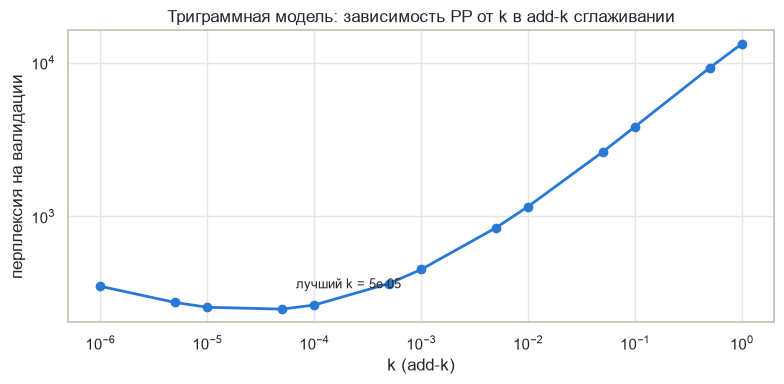

In [33]:
lm3_comb, best_alpha3, best_l3, alpha_pp3 = models_comb[3]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(list(alpha_pp3), list(alpha_pp3.values()), marker="o", color=CLASS_COLORS[0], lw=2)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("k (add-k)")
ax.set_ylabel("перплексия на валидации")
ax.set_title("Триграммная модель: зависимость PP от k в add-k сглаживании")
ax.annotate(f"лучший k = {best_alpha3}", (best_alpha3, alpha_pp3[best_alpha3]),
            textcoords="offset points", xytext=(10, 15), fontsize=9)
plt.tight_layout()
plt.show()

Почему Лаплас так плох: посмотрим, какую долю вероятностной массы add-one отдаёт невиденным триграммам в типичном контексте.

In [34]:
uk, uc, ck, cc = lm3_comb.counts[3]
V_out = lm3_comb.V_out
n_seen_cont = np.unique(uk // lm3_comb.V, return_counts=True)[1]  # число разных продолжений у контекста
# для контекста h: масса невиденных = (V_out - T(h)) * k / (c(h) + k*V_out)
for k_ in (1.0, best_alpha3):
    mass_unseen = (V_out - n_seen_cont) * k_ / (cc + k_ * V_out)
    print(f"k={k_}: медианная доля массы на невиденные продолжения = {np.median(mass_unseen):.3f}, "
          f"взвешенная по частоте контекста = {np.average(mass_unseen, weights=cc):.3f}")
print(f"|V| = {V_out:,}; медианная частота контекста c(h) = {np.median(cc):.0f}, "
      f"медианное число разных продолжений T(h) = {np.median(n_seen_cont):.0f}")

k=1.0: медианная доля массы на невиденные продолжения = 1.000, взвешенная по частоте контекста = 0.979
k=5e-05: медианная доля массы на невиденные продолжения = 0.851, взвешенная по частоте контекста = 0.378
|V| = 114,224; медианная частота контекста c(h) = 1, медианное число разных продолжений T(h) = 1


Для сравнения — та же процедура на **сыром** корпусе (со стоп-словами).

In [35]:
docs_train_raw = [c.split() for c in raw_train["clean"]]
docs_test_raw = [c.split() for c in raw_test["clean"]]
t0 = time.time()
res_raw, models_raw = lm_experiment(docs_train_raw, docs_test_raw, "сырой корпус")
print(f"{time.time() - t0:.0f} c")
pd.concat({"phishing_email.csv": res_comb, "сырой корпус": res_raw}, axis=1)

сырой корпус: словарь 97,555, токенов train 16,394,101
32 c


phishing_email.csv  \
                                                       N=2   
доля невиденных n-грамм в test                    0.186982   
доля невиденных контекстов                             0.0   
PP: MLE (без сглаживания)                              inf   
PP: MLE только по p>0 (некорректно!)             91.123477   
PP: Лаплас (k=1)                               6685.080674   
PP: add-k (лучший k на val)                     609.559557   
PP: интерполяция (λ на val)                     385.598337   
лучший k                                             0.001   
λ (uniform, 1-, 2-, 3-грамма)         (0.01, 0.198, 0.792)   

                                                                   \
                                                              N=3   
доля невиденных n-грамм в test                           0.376816   
доля невиденных контекстов                               0.186494   
PP: MLE (без сглаживания)                                     inf   
PP: MLE только по p>0 (некорректно!)                      3.58071   
PP: Лаплас (k=1)                                     18128.368351   
PP: add-k (лучший k на val)                            312.087395   
PP: интерполяция (λ на val)                             94.991105   
лучший k                                                  0.00005   
λ (uniform, 1-, 2-, 3-грамма)         (0.01, 0.198, 0.198, 0.594)   

                                              сырой корпус  \
                                                       N=2   
доля невиденных n-грамм в test                    0.090423   
доля невиденных контекстов                             0.0   
PP: MLE (без сглаживания)                              inf   
PP: MLE только по p>0 (некорректно!)               96.1726   
PP: Лаплас (k=1)                               1697.702197   
PP: add-k (лучший k на val)                     249.678425   
PP: интерполяция (λ на val)                     202.882274   
лучший k                                             0.001   
λ (uniform, 1-, 2-, 3-грамма)         (0.01, 0.099, 0.891)   

                                                                   
                                                              N=3  
доля невиденных n-грамм в test                            0.25664  
доля невиденных контекстов                               0.090152  
PP: MLE (без сглаживания)                                     inf  
PP: MLE только по p>0 (некорректно!)                     8.482354  
PP: Лаплас (k=1)                                      8526.412349  
PP: add-k (лучший k на val)                             159.35747  
PP: интерполяция (λ на val)                             58.288078  
лучший k                                                  0.00005  
λ (uniform, 1-, 2-, 3-грамма)         (0.01, 0.099, 0.198, 0.693)

### Выводы по сглаживанию и перплексии

Основной корпус: словарь модели — 114 225 токенов (частота ≥ 3), доля `[UNK]` в test — 4,2%.

| | N=2 | N=3 |
|---|---|---|
| невиденные n-граммы в test | 18,7% | 37,7% |
| MLE без сглаживания | **∞** | **∞** |
| Лаплас (k=1) | 6 685 | 18 128 |
| add-k (k подобран на val) | 610 | 312 |
| интерполяция | 386 | **95** |

**1. Без сглаживания PP = ∞.** $PP = \exp\left(-\frac1N\sum\log p_i\right)$. 37,7% триграмм test ни разу не встречались в train, для них $p_i = c/c(h) = 0$ и $\log p_i = -\infty$. Сумма логарифмов равна $-\infty$, значит $PP = e^{+\infty} = \infty$; для этого достаточно **одной** нулевой вероятности. У 18,6% триграмм не встречался даже контекст: там $0/0$, и вероятность вовсе не определена. Строка «PP только по p>0» (3,6) — некорректная метрика: мы выбросили ровно самые трудные токены, это смещённая выборка.

**2. Лаплас (add-one) формально решает проблему, но практически бесполезен.** В контексте $h$ на невиденные продолжения уходит масса $\frac{(|V|-T(h))\,k}{c(h)+k|V|}$, где $T(h)$ — число разных продолжений. У нас $|V| \approx 114$ тыс., а медианный контекст встречается $c(h)=1$ раз с $T(h)=1$ продолжением. При $k=1$ увиденной триграмме достаётся $\frac{1+1}{1+114\,224} \approx 1{,}75\cdot10^{-5}$ вместо 1, а невиденным — 97,9% массы (взвешенно по контекстам). Модель почти равномерна, и её PP = 18 тыс. стремится к $|V|$. Триграммная модель с Лапласом хуже биграммной: триграммные контексты разреженнее, и искажение сильнее.

**3. Add-k с малым k.** Оптимум $k = 5\cdot10^{-5}$ даёт PP = 312. При этом k на невиденные уходит 37,8% массы — почти ровно столько, сколько в test реально невиденных триграмм (37,7%). Оптимальный k калибрует «резерв» вероятности под истинную долю новых событий. Но add-k раздаёт этот резерв **равномерно** по всем 114 тыс. словам — `the` и случайный хэш получают одинаковую долю.

**4. Интерполяция лучше всех (PP = 95 против 312).** Для невиденной триграммы она даёт не равномерную оценку, а взвешенную сумму биграммной и униграммной: $\lambda_2 P(w|w_{-1}) + \lambda_1 P(w)$. Частые слова получают больше массы. Подобранные веса — λ₃ = 0,59, λ₂ = 0,20, λ₁ = 0,20, λ₀ = 0,01. Переход от N=2 к N=3 снижает PP в 4 раза (386 → 95) только при таком комбинировании; без него длинный контекст из-за разреженности только вредит.

**5. Сравнение корпусов.** На сыром корпусе (со стоп-словами) у триграммной интерполированной модели PP = 58, невиденных триграмм — 25,7%. Служебные слова хорошо предсказуемы и уплотняют статистику. Прямое сравнение PP разных корпусов, впрочем, некорректно: у них разные словари и разные последовательности токенов.

## 9. Генерация текстов (марковская цепь)

Генерация по триграммной модели: начинаем с контекста `<s> <s>`, на каждом шаге сэмплируем следующее слово из распределения $P_{MLE}(w|w_{i-2}w_{i-1})$ (несглаженные счётчики — сглаживание при генерации добавило бы шум из равномерного распределения), останавливаемся на `</s>` или по достижении `max_len`. Токен `[UNK]` запрещаем к генерации (перенормируем распределение), иначе текст заполнялся бы «дырами». Если после запрета у контекста не осталось продолжений (единственным продолжением был `[UNK]`), делаем откат (backoff) к более короткому контексту — биграмме, затем униграмме.

In [36]:
def generate(lm, max_len=40, rng=None, ban_unk=True):
    rng = rng or np.random.default_rng()
    hist = [lm.bos] * (lm.n - 1)
    out, finished = [BOS], False
    while len(out) - 1 < max_len:
        for k in range(lm.n, 0, -1):          # backoff: n-грамма -> ... -> униграмма
            uk, uc, _, _ = lm.counts[k]
            c = 0
            for t in hist[len(hist) - (k - 1):] if k > 1 else []:
                c = c * lm.V + t
            lo, hi = np.searchsorted(uk, c * lm.V), np.searchsorted(uk, (c + 1) * lm.V)
            nxt, w = uk[lo:hi] % lm.V, uc[lo:hi].astype(float)
            if ban_unk:
                w[nxt == lm.unk] = 0
            if w.sum() > 0:
                break
        t = int(rng.choice(nxt, p=w / w.sum()))
        out.append(lm.itos[t])
        if t == lm.eos:
            finished = True
            break
        hist = hist[1:] + [t]
    return " ".join(out), finished

rng = np.random.default_rng(SEED)
print("=== Триграммная модель, phishing_email.csv ===")
for i in range(5):
    text, fin = generate(lm3_comb, max_len=40, rng=rng)
    print(f"{i+1}. {text}" + ("" if fin else "  …[max_len]"), "\n")

=== Триграммная модель, phishing_email.csv ===
1. <s> fredrick barker dozhixyupvhnplcouk print map nl 1nl nl [NUM] pending messages inbox youre writing emails friends contacts see latest creation thu [NUM] jul [NUM] palo p jan [NUM] cnncom daily top [NUM] go [URL] unsubscribe [URL] wed [NUM] aug [NUM]  …[max_len] 

2. <s> nick murtagh go2web ltd harbour house harbour road howth dublin [NUM] [URL] p2p scammers lawyers attack open source software business profitable companies year invest stocks live live anything volatile objective building portfolio try approximate [NUM] million credit linked notes reflect  …[max_len] 

3. <s> perl5 bug summary </s> 

4. <s> new services suggestion thanks advanced penghui wang tested via sendmail command wont work like example txtfile brbr freeware [NUM] decade definite package notes contents information manipulation manipulate judd kapok crotchety balfour time thu [NUM] aug [NUM] presentation attached </s> 

5. <s> nan top quality software looking seco

In [37]:
lm3_raw = models_raw[3][0]
print("=== Триграммная модель, сырой корпус (для сравнения) ===")
for i in range(5):
    text, fin = generate(lm3_raw, max_len=40, rng=rng)
    print(f"{i+1}. {text}" + ("" if fin else "  …[max_len]"), "\n")

=== Триграммная модель, сырой корпус (для сравнения) ===
1. <s> you can click here cable news network one cnn center atlanta georgia [NUM] [NUM] 49am pst orange access join the dynegy talks go on to others this difference in the debugging but this does nothing and everything else feels he  …[max_len] 

2. <s> re [NUM] [NUM] [NUM] security [URL] [NUM] mountain lion in bedroom kills dog [URL] [NUM] ireporters unusual names [URL] [NUM] canon powershot s30 [URL] [NUM] commentary bill clinton's upset [URL] [NUM] ireporters unusual names [URL] [NUM] on vms because it  …[max_len] 

3. <s> high quality nfs servers it's a bug report guys i've checked in i'm afraid and i don't like vista the discussion saw les argue [NUM] that the company your company name louise there are two sides remain locked in to  …[max_len] 

4. <s> re sa learn and also provide the minimum of assumptions and describe future pians strategies and expectations involving various risks and uncertainties which could cause resul

Дополнительно: модели, обученные отдельно на фишинговых и легитимных письмах основного корпуса — генерация хорошо показывает «стиль» каждого класса.

In [38]:
for lbl in (1, 0):
    docs_lbl = [d for d, y in zip(docs_train, train_df[TARGET]) if y == lbl]
    lm_lbl = NGramLM(3, build_vocab(docs_lbl, MIN_COUNT)).fit(docs_lbl)
    print(f"=== {CLASS_NAMES[lbl]} ===")
    for i in range(3):
        text, fin = generate(lm_lbl, max_len=30, rng=rng)
        print(f"{i+1}. {text}" + ("" if fin else "  …[max_len]"))
    print()

=== фишинг (1) ===
1. <s> daily top [NUM] videos [NUM] paris hilton swings back republican presidential candidate john mccain kareen wynter reports [NUM] bikini barista stand closed [URL] [NUM] hecklers interrupt obama talk [URL] top  …[max_len]
2. <s> evan love triangle murder [URL] [NUM] commentary bill clintons upset [URL] [NUM] lure rrated comedy [URL] [NUM] killer carried victims head [URL] [NUM] john junior gotti arrested [URL] [NUM] news  …[max_len]
3. <s> daily top [NUM] cnncom daily top [NUM] stories [NUM] smoke forces emergency landing [URL] passengers evacuate american airlines jet inflatable slides emergency landing los angeles ca [NUM] </s>



=== легитимные (0) ===
1. <s> torcom tebrqgxittorcom view email web instant messaging collaboration means hefty licensing support fees sophisticated features knowledge workers use corporate mail private confidential may privileged unauthorized disclosure copying distribution use contents  …[max_len]
2. <s> operations pricing model would next though things turn nonetheless striking four languages instances known posted query linguist list query parallel corpora udo hahn jena university language tutorial turkish given jaklin  …[max_len]
3. <s> wesley [NUM] direct message phone im spamexperts message turn email notifications [URL] fri [NUM] aug [NUM] spambayesbugs1600821 classifier unicodedecodeerror wrong transfer encoding initial comment first save line [NUM] ioerror selfrunning  …[max_len]



### Оценка сгенерированных текстов

**Модель на `phishing_email.csv`:**
* **Грамматическая связность** — только **локальная**, в окне 2–3 слов: `pending messages inbox`, `second mortgage home equity loan low fixed rate`, `harbour house harbour road howth dublin`. В обучающем тексте нет стоп-слов, поэтому даже правильные фрагменты звучат как «телеграф» или набор ключевых слов. Говорить о грамматике предложения здесь не приходится.
* **Смысловая адекватность низкая.** Тема меняется каждые 3–5 слов: ипотечный спам → энергетика Enron → лингвистика → новости CNN. Причина — марковское свойство: модель помнит только 2 предыдущих слова, глобального плана текста у неё нет.
* **Структура письма отражается правдоподобно.** Тексты часто начинаются с имени отправителя (`fredrick barker`, `nick murtagh`), как реальные письма с заголовками; встречаются `[URL]`, `[NUM]`, `unsubscribe`. Короткие тексты (`perl5 bug summary`) корректно завершаются `</s>`, длинные упираются в `max_len`.
* **Видны артефакты данных**: склеенные домены (`dozhixyupvhnplcouk`) и токен `nan`.

**Модель на сыром корпусе** заметно грамматичнее благодаря служебным словам. Фрагменты вроде `describe future pians strategies and expectations involving various risks and uncertainties which could cause results to differ materially from those …` выглядят как настоящий текст: это почти дословная цитата юридического дисклеймера из биржевого спама, частотные триграммы воспроизводят устойчивые шаблоны. Обфускация `pians` (вместо `plans`) скопирована из спам-рассылки. Но смысл так же распадается — нигерийское письмо переходит в Enron, затем в новости.

**Модели по классам** показывают «стиль» классов. Фишинговая почти всегда воспроизводит шаблон фейковой рассылки «CNN Daily Top 10» — это самый массовый спам-шаблон в CEAS и одновременно источник пиков на гистограмме длин. Легитимная генерирует служебную переписку, списки рассылки и академические анонсы.

**Итог.** N-граммная модель хорошо улавливает локальную сочетаемость и устойчивые шаблоны, но не порождает связный текст. Для этого нужны больший контекст (что упирается в разреженность — см. п. 8) или нейросетевые языковые модели.